# E-commerce Customer Segmentation and Behavioral Analysis Using Unsupervised Machine Learning

## 1. Problem Definition

E-commerce businesses serve customers with different purchasing behaviors, spending patterns, and levels of engagement. Treating all customers identically can make it difficult to design effective marketing strategies and retain valuable customers.

The objective of this project is to apply unsupervised machine learning to group customers based on their purchasing behavior using historical transaction data.

The project uses Recency, Frequency, and Monetary (RFM) analysis to construct customer-level features and applies clustering algorithms to identify meaningful customer segments.

### 1.2 Project Objectives

- Collect and explore a real-world retail transaction dataset.
- Clean the data and handle missing values, invalid records, and cancelled transactions.
- Perform exploratory data analysis and feature engineering.
- Develop customer segments using K-Means clustering.
- Evaluate clustering quality and optimize model parameters.
- Visualize customer groups and interpret their purchasing behavior.
- Document the methodology, results, limitations, and conclusions.

###1.3 Technologies Used

Python, Google Colab, Pandas, NumPy, Matplotlib, Seaborn, and Scikit-learn.


##2. Dataset Collection

###2.1 Dataset Introduction
The UCI Online Retail dataset contains transactional data from a UK-based online retail store. The store primarily sells unique all-occasion gifts, and many of its customers are wholesalers.

Dataset source: https://archive.ics.uci.edu/dataset/352/online+retail



###2.2 Dataset Overview

In [1]:
import os

# Display files available in the current Colab environment
print("Files available in Google Colab:\n")

for file in os.listdir("/content"):
    print(file)

Files available in Google Colab:

.config
.ipynb_checkpoints
Online Retail.xlsx
sample_data


###2.3 Importing the Required Libraries

In [2]:
# Import libraries for data analysis
import pandas as pd
import numpy as np

# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Import libraries for machine learning
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

print("All required libraries imported successfully!")

All required libraries imported successfully!


###2.4 Loading the Dataset

In [3]:
# Load the Online Retail dataset
file_path = "/content/Online Retail.xlsx"

df = pd.read_excel(file_path)

print("Dataset loaded successfully!")
print("Dataset is stored in the DataFrame 'df'.")

Dataset loaded successfully!
Dataset is stored in the DataFrame 'df'.


##3. Data Preparation

###3.1 Inspecting the Dataset

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


###3.2 Missing Values

In [6]:
missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage (%)': (missing_values / len(df)) * 100
})

missing_summary[missing_summary['Missing Values'] > 0]

,Missing Values,Percentage (%)
Description,1454,0.268311
CustomerID,135080,24.926694


###3.3 Duplicate Values

In [7]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 5268


###3.4 Checking Transaction Records

In [8]:
print("Cancelled transactions:", df['InvoiceNo'].astype(str).str.startswith('C').sum())

Cancelled transactions: 9288


###3.5 Checking Invalid Transaction Values

In [9]:
print("Zero or negative quantities:", (df['Quantity'] <= 0).sum())
print("Zero unit prices:", (df['UnitPrice'] == 0).sum())
print("Negative unit prices:", (df['UnitPrice'] < 0).sum())

Zero or negative quantities: 10624
Zero unit prices: 2515
Negative unit prices: 2


###3.6 Preparing for Customer-Level Segmentation

In [10]:
df[['InvoiceNo', 'InvoiceDate', 'CustomerID', 'Quantity', 'UnitPrice']].head()

,InvoiceNo,InvoiceDate,CustomerID,Quantity,UnitPrice
0,536365,2010-12-01 08:26:00,17850.0,6,2.55
1,536365,2010-12-01 08:26:00,17850.0,6,3.39
2,536365,2010-12-01 08:26:00,17850.0,8,2.75
3,536365,2010-12-01 08:26:00,17850.0,6,3.39
4,536365,2010-12-01 08:26:00,17850.0,6,3.39


###3.7 Checking the Dataset's Time Range

In [11]:
print("First transaction date:", df['InvoiceDate'].min())
print("Last transaction date:", df['InvoiceDate'].max())

First transaction date: 2010-12-01 08:26:00
Last transaction date: 2011-12-09 12:50:00


##4. Data Preprocessing

###4.1 Handling Missing Values

In [12]:

# Remove records with missing CustomerID
df = df.dropna(subset=['CustomerID'])

# Check the updated dataset
print("Dataset shape after removing missing CustomerID values:", df.shape)
print("Missing CustomerID values:", df['CustomerID'].isnull().sum())
print("Missing Description values:", df['Description'].isnull().sum())


Dataset shape after removing missing CustomerID values: (406829, 8)
Missing CustomerID values: 0
Missing Description values: 0


###4.2 Removing Duplicate Records

In [13]:

# Remove duplicate records
df = df.drop_duplicates()

# Check the updated dataset
print("Dataset shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Dataset shape after removing duplicates: (401604, 8)
Remaining duplicate rows: 0


###4.3 Handling Cancelled Transactions

In [14]:

# Remove cancelled transactions
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')].copy()

# Check the updated dataset
print("Dataset shape after removing cancelled transactions:", df.shape)
print("Remaining cancelled transactions:",
      df['InvoiceNo'].astype(str).str.startswith('C').sum())


Dataset shape after removing cancelled transactions: (392732, 8)
Remaining cancelled transactions: 0


###4.4 Handling Invalid Quantities and Unit Prices

In [15]:

# Keep transactions with positive quantities and unit prices
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)].copy()

# Check the updated dataset
print("Dataset shape after removing invalid values:", df.shape)
print("Non-positive quantities:", (df['Quantity'] <= 0).sum())
print("Non-positive unit prices:", (df['UnitPrice'] <= 0).sum())


Dataset shape after removing invalid values: (392692, 8)
Non-positive quantities: 0
Non-positive unit prices: 0


###4.5 Creating a Transaction Value Feature

In [16]:

# Calculate the total value of each transaction line
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

# Display the updated dataset
display(df.head())

print("Updated dataset shape:", df.shape)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


Updated dataset shape: (392692, 9)


###4.6 Preparing Customer-Level RFM Features

In [17]:
# Set the reference date
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

# Calculate customer-level RFM features
rfm = df.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (reference_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalPrice', 'sum')
).reset_index()

# Display the customer-level RFM dataset
display(rfm.head())

print("RFM dataset shape:", rfm.shape)

,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


RFM dataset shape: (4338, 4)


###4.7 Checking RFM Features Statistics

In [18]:
# Display summary statistics of RFM features
display(rfm[['Recency', 'Frequency', 'Monetary']].describe().round(2))

,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
max,374.00,209.00,280206.02


###4.8 Handling Skewness in RFM Features

In [19]:
# Apply logarithmic transformation to RFM features
rfm_log = rfm[['Recency', 'Frequency', 'Monetary']].apply(
    np.log1p
)

# Check the transformed feature distributions
display(rfm_log.describe().round(2))

,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,3.83,1.35,6.59
std,1.34,0.68,1.26
min,0.69,0.69,1.56
25%,2.94,0.69,5.73
50%,3.95,1.10,6.51
75%,4.96,1.79,7.42
max,5.93,5.35,12.54


###4.9 Feature Scaling

In [20]:

# Standardize the transformed RFM features
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_log)

# Check the scaled feature statistics
rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=['Recency', 'Frequency', 'Monetary']
)

display(rfm_scaled_df.describe().round(2))


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,-0.00,-0.00,-0.00
std,1.00,1.00,1.00
min,-2.34,-0.96,-4.00
25%,-0.66,-0.96,-0.68
50%,0.09,-0.36,-0.07
75%,0.84,0.65,0.66
max,1.56,5.86,4.73


##5. Data Visualization

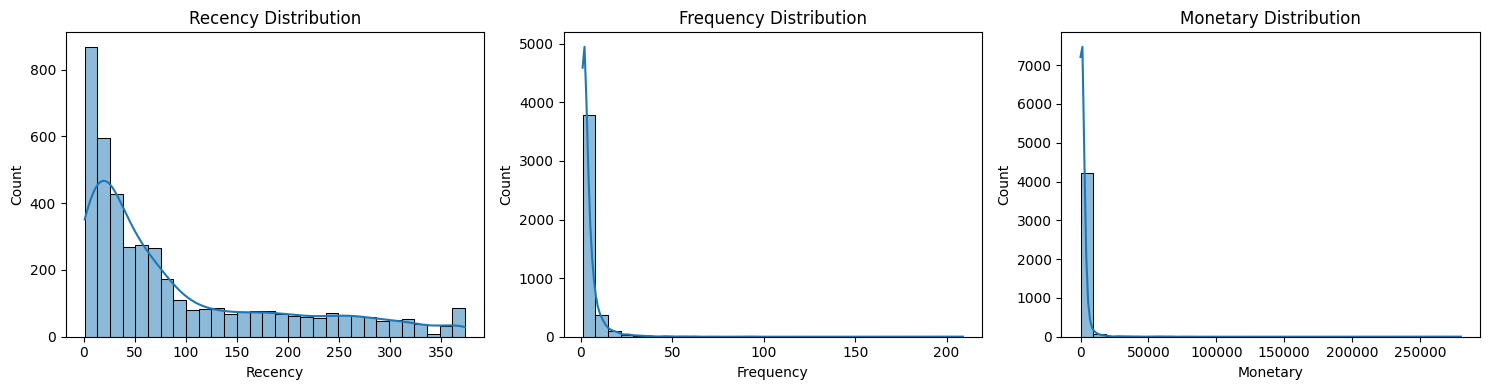

In [21]:
# Visualize the distributions of RFM features
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column in zip(axes, ['Recency', 'Frequency', 'Monetary']):
    sns.histplot(data=rfm, x=column, bins=30, kde=True, ax=ax)
    ax.set_title(f'{column} Distribution')

plt.tight_layout()
plt.show()

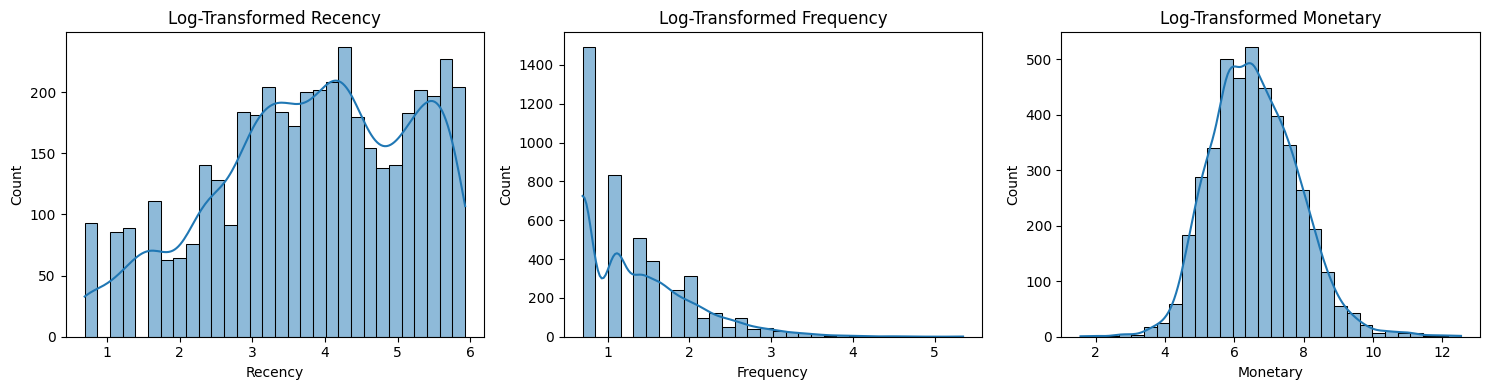

In [22]:
# Visualize the log-transformed RFM features
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column in zip(axes, ['Recency', 'Frequency', 'Monetary']):
    sns.histplot(rfm_log[column], bins=30, kde=True, ax=ax)
    ax.set_title(f'Log-Transformed {column}')

plt.tight_layout()
plt.show()

##6. Model Development and Clustering

###6.1 Finding Optimal Number of Clusters

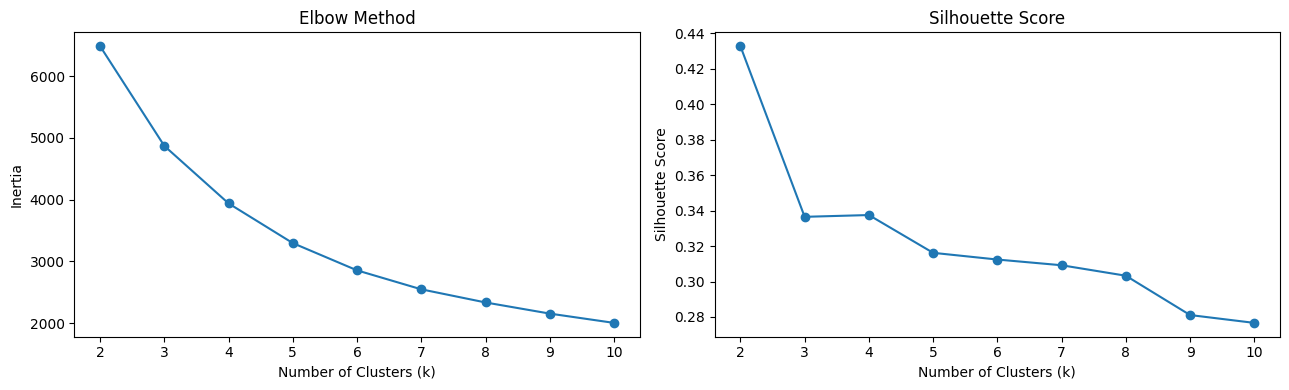

Silhouette scores:
k = 2: 0.4328
k = 3: 0.3365
k = 4: 0.3375
k = 5: 0.3162
k = 6: 0.3124
k = 7: 0.3092
k = 8: 0.3033
k = 9: 0.2811
k = 10: 0.2767


In [23]:
# Evaluate different numbers of clusters
inertia_values = []
silhouette_scores = []
k_values = range(2, 11)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(rfm_scaled)

    inertia_values.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(rfm_scaled, labels))

# Plot both evaluation metrics
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(k_values, inertia_values, marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')

axes[1].plot(k_values, silhouette_scores, marker='o')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

print("Silhouette scores:")
for k, score in zip(k_values, silhouette_scores):
    print(f"k = {k}: {score:.4f}")

###6.2 Training the K-Means Model

In [24]:
# Train the K-Means model with 4 clusters
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

# Check the number of customers in each cluster
print("Customers in each cluster:")
print(rfm['Cluster'].value_counts().sort_index())

# Display the first few assigned customers
display(rfm.head())

Customers in each cluster:
Cluster
0     713
1    1622
2     837
3    1166
Name: count, dtype: int64


,CustomerID,Recency,Frequency,Monetary,Cluster
0,12346.0,326,1,77183.60,3
1,12347.0,2,7,4310.00,0
2,12348.0,75,4,1797.24,3
3,12349.0,19,1,1757.55,2
4,12350.0,310,1,334.40,1


###6.3 Analyzing Customers Cluster

In [25]:
# Summarize RFM characteristics for each cluster
cluster_summary = rfm.groupby('Cluster').agg(
    CustomerCount=('CustomerID', 'count'),
    AvgRecency=('Recency', 'mean'),
    AvgFrequency=('Frequency', 'mean'),
    AvgMonetary=('Monetary', 'mean')
).round(2)

display(cluster_summary)

,CustomerCount,AvgRecency,AvgFrequency,AvgMonetary
Cluster,,,,
0,713,12.17,13.75,8088.02
1,1622,181.51,1.32,341.00
2,837,17.70,2.19,557.32
3,1166,71.64,4.08,1801.78


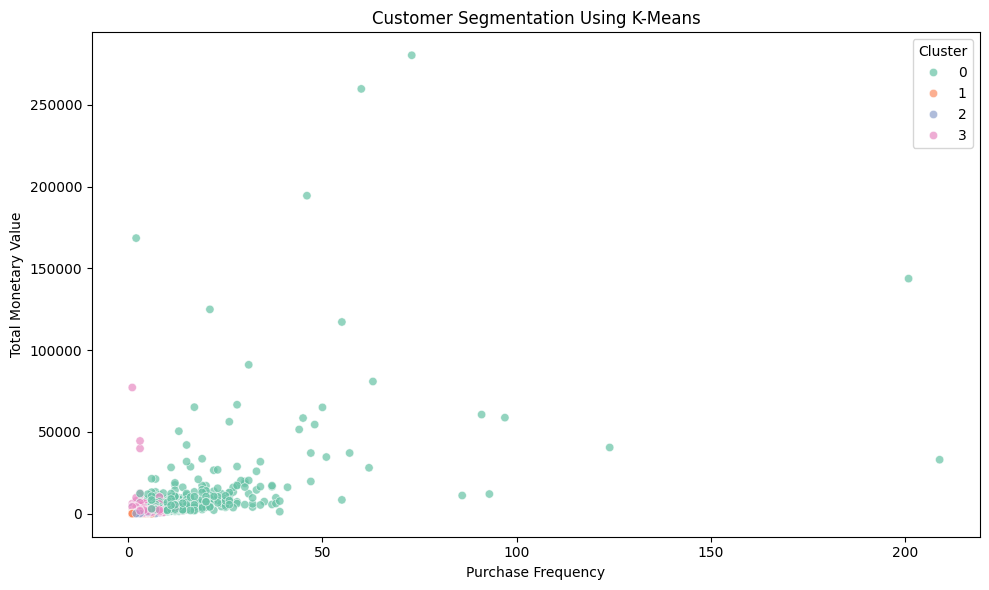

In [26]:
# Visualize customer clusters
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='Set2',
    alpha=0.7
)

plt.title('Customer Segmentation Using K-Means')
plt.xlabel('Purchase Frequency')
plt.ylabel('Total Monetary Value')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

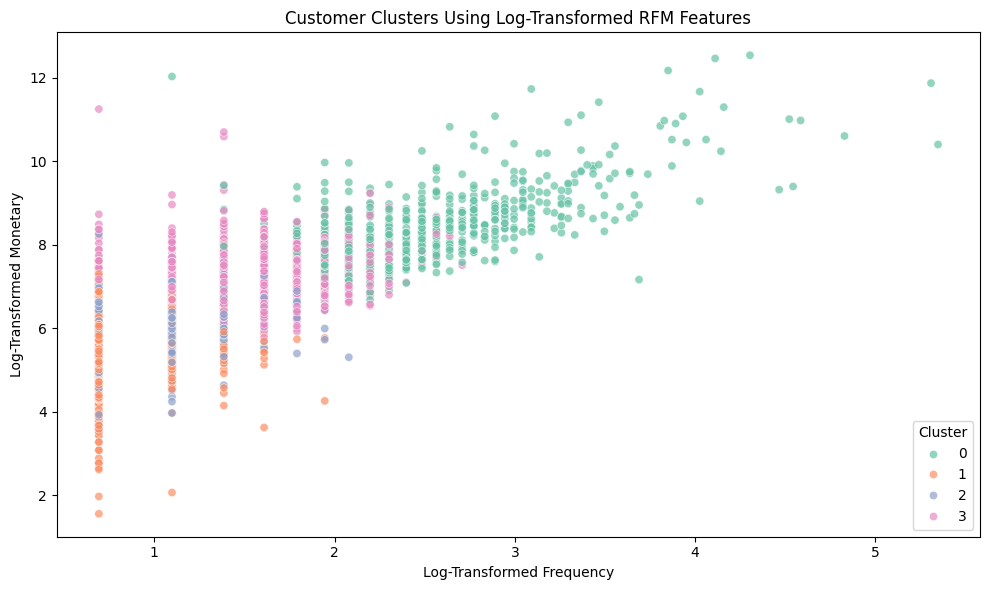

In [27]:
# Create a visualization-friendly dataset
plot_df = rfm_log.copy()
plot_df['Cluster'] = rfm['Cluster'].values

# Plot clusters using log-transformed features
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_df,
    x='Frequency',
    y='Monetary',
    hue='Cluster',
    palette='Set2',
    alpha=0.7
)

plt.title('Customer Clusters Using Log-Transformed RFM Features')
plt.xlabel('Log-Transformed Frequency')
plt.ylabel('Log-Transformed Monetary')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

In [28]:
# Evaluate the final four-cluster solution
final_silhouette = silhouette_score(rfm_scaled, rfm['Cluster'])

print(f"Number of clusters: {rfm['Cluster'].nunique()}")
print(f"Number of customers: {len(rfm)}")
print(f"Silhouette Score: {final_silhouette:.4f}")

print("\nCustomer count and percentage by cluster:")
cluster_distribution = rfm['Cluster'].value_counts().sort_index().to_frame(
    name='CustomerCount'
)
cluster_distribution['Percentage'] = (
    cluster_distribution['CustomerCount'] / len(rfm) * 100
).round(2)

display(cluster_distribution)

Number of clusters: 4
Number of customers: 4338
Silhouette Score: 0.3375

Customer count and percentage by cluster:


,CustomerCount,Percentage
Cluster,,
0,713,16.44
1,1622,37.39
2,837,19.29
3,1166,26.88


### Performance Evaluation
The K-Means model was evaluated using the Elbow Method and Silhouette Score. The four-cluster model achieved a Silhouette Score of 0.3375, indicating moderate separation between customer groups. The cluster distribution and RFM profiles were also examined to understand the characteristics of each customer segment.

## 7. Result Analysis

The K-Means clustering algorithm successfully grouped 4,338 customers into four distinct segments based on their Recency, Frequency, and Monetary (RFM) values.

- **Cluster 0 – High-Value Customers:** 713 customers (16.44%) demonstrated the highest average purchase frequency and monetary value, indicating strong customer engagement and spending.
- **Cluster 1 – Low-Engagement Customers:** 1,622 customers (37.39%) had the highest average recency, lowest purchase frequency, and lowest monetary value. Targeted marketing campaigns could help encourage repeat purchases.
- **Cluster 2 – Recent, Lower-Spending Customers:** 837 customers (19.29%) had relatively recent purchases but lower average frequency and spending, presenting opportunities to encourage further purchases.
- **Cluster 3 – Moderate-Value Customers:** 1,166 customers (26.88%) showed moderate purchasing frequency and monetary value, offering opportunities to strengthen customer engagement and increase spending.

The four-cluster model achieved a Silhouette Score of **0.3375**, indicating moderate separation between customer groups. Although a two-cluster solution achieved a higher score, the four-cluster model provides more detailed customer profiles for business analysis.

Overall, the results demonstrate that RFM-based K-Means clustering can effectively organize customers into meaningful groups based on their purchasing patterns. These segments can help businesses develop personalized marketing strategies, improve customer engagement, identify high-value customers, and allocate promotional resources more effectively. The analysis demonstrates the practical application of unsupervised machine learning in e-commerce customer relationship management.